# Задача 9: Множества Жюлиа

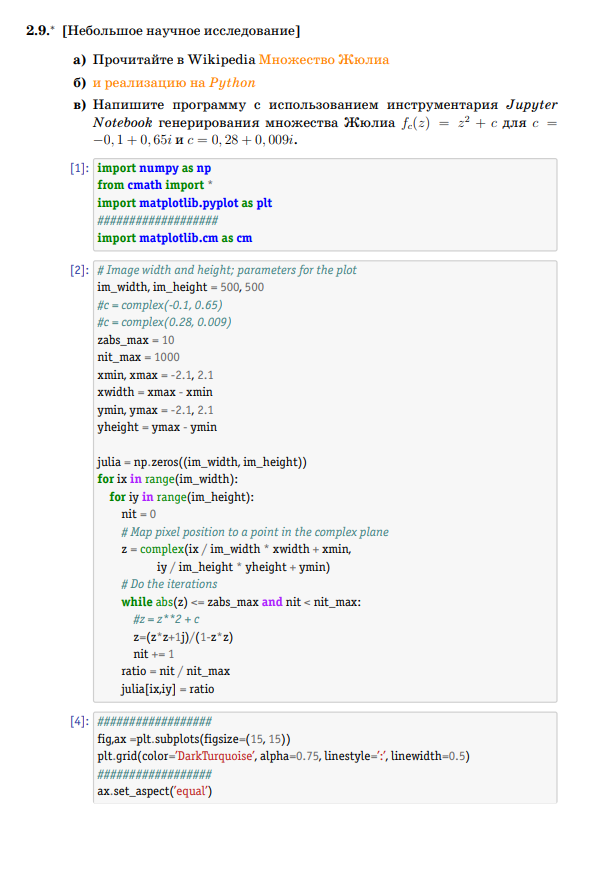
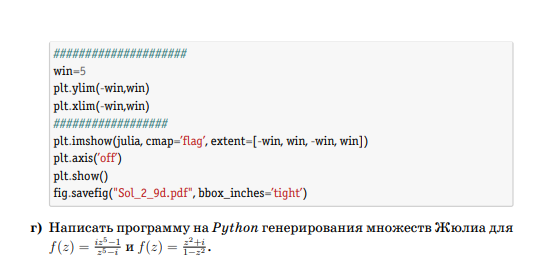

## Математическая база

### Динамические системы на комплексной плоскости

Для функции $f: \mathbb{C} \to \mathbb{C}$ и точки $z_0$ определим орбиту:

$$z_0, \quad z_1 = f(z_0), \quad z_2 = f^{\circ 2}(z_0), \quad \ldots, \quad z_n = f^{\circ n}(z_0)$$

### Множество Жюлиа и множество Фату

**Множество Жюлиа** $J(f)$ — множество точек, в которых семейство итераций $\{f^{\circ n}\}$ не является нормальным (орбиты хаотичны).

**Множество Фату** $F(f) = \mathbb{C} \setminus J(f)$ — множество точек с регулярным поведением орбит.

### Множество Жюлиа для $f_c(z) = z^2 + c$

**Теорема.** Если $|f_c^{\circ n}(z)| > 2$ для некоторого $n$, то орбита уходит в бесконечность.

**Заполненное множество Жюлиа:**
$$K(f_c) = \{z \in \mathbb{C} : \{f_c^{\circ n}(z)\} \text{ ограничена}\}$$

**Множество Жюлиа:** $J(f_c) = \partial K(f_c)$ (граница заполненного множества).

### Связь с множеством Мандельброта

$$M = \{c \in \mathbb{C} : \{f_c^{\circ n}(0)\} \text{ ограничена}\}$$

- $c \in M \implies J(f_c)$ связно
- $c \notin M \implies J(f_c)$ несвязно (пыль Кантора)

### Обобщение на рациональные функции

Для $f(z) = P(z)/Q(z)$ определение сохраняется на расширенной комплексной плоскости $\hat{\mathbb{C}}$. Необходимо обрабатывать полюса ($Q(z) = 0$) и исключения переполнения.

### Свойства множеств Жюлиа

| Свойство | Описание |
|:---:|:---|
| Инвариантность | $f(J(f)) = J(f) = f^{-1}(J(f))$ |
| Замкнутость | $J(f)$ всегда замкнуто |
| Совершенность | Нет изолированных точек |
| Фрактальность | Дробная размерность Хаусдорфа |


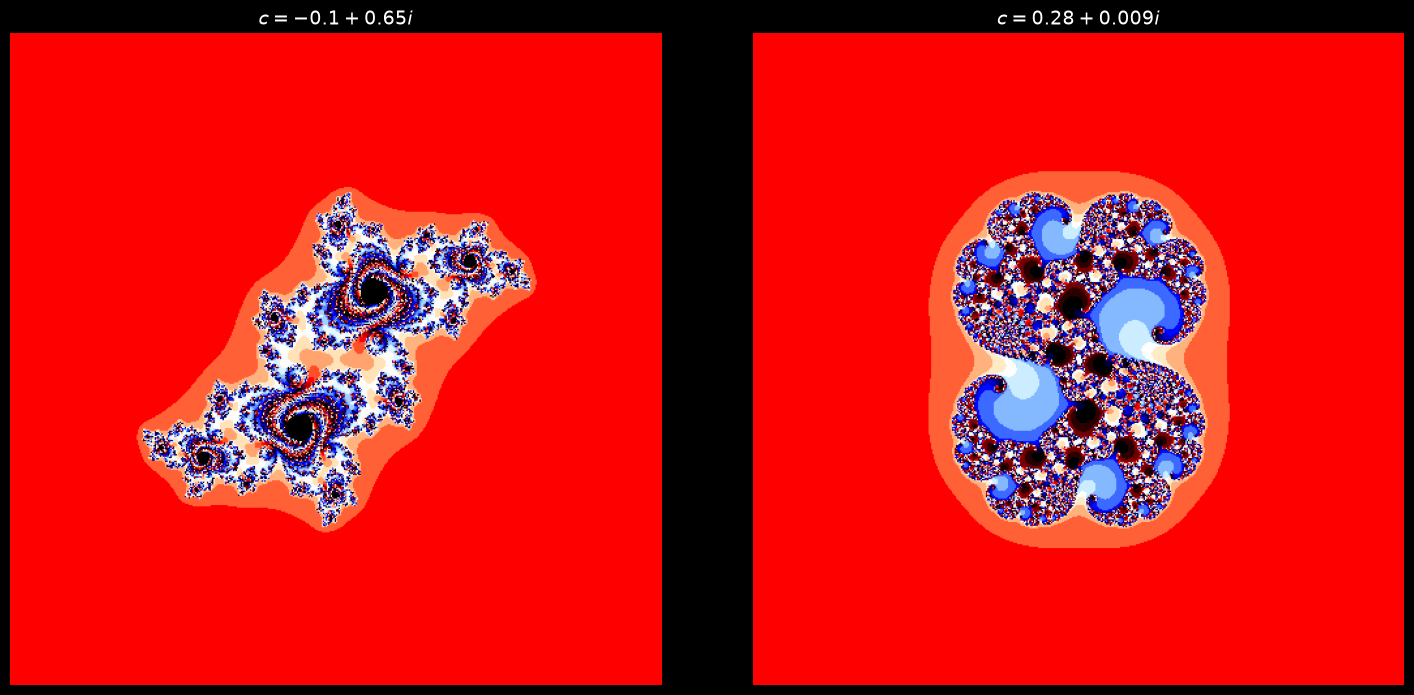

In [3]:
import numpy as np
from cmath import *
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def julia_set(c, im_width=500, im_height=500,
              xmin=-2.1, xmax=2.1, ymin=-2.1, ymax=2.1,
              zabs_max=10, nit_max=1000):
    xwidth = xmax - xmin
    yheight = ymax - ymin
    julia = np.zeros((im_width, im_height))

    for ix in range(im_width):
        for iy in range(im_height):
            nit = 0
            # Маппинг пикселя в точку комплексной плоскости
            z = complex(ix / im_width * xwidth + xmin,
                        iy / im_height * yheight + ymin)
            # Итерации z = z^2 + c
            while abs(z) <= zabs_max and nit < nit_max:
                z = z * z + c
                nit += 1
            ratio = nit / nit_max
            julia[ix, iy] = ratio
    return julia

# c = -0.1 + 0.65i
c1 = complex(-0.1, 0.65)
julia1 = julia_set(c1)

# c = 0.28 + 0.009i
c2 = complex(0.28, 0.009)
julia2 = julia_set(c2)

# Построение графиков
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

win = 2.1
axes[0].imshow(julia1.T, cmap='flag', extent=[-win, win, -win, win])
axes[0].set_title(r'$c = -0.1 + 0.65i$', fontsize=14)
axes[0].axis('off')

axes[1].imshow(julia2.T, cmap='flag', extent=[-win, win, -win, win])
axes[1].set_title(r'$c = 0.28 + 0.009i$', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.savefig("Sol_2_9c.pdf", bbox_inches='tight')
plt.show()

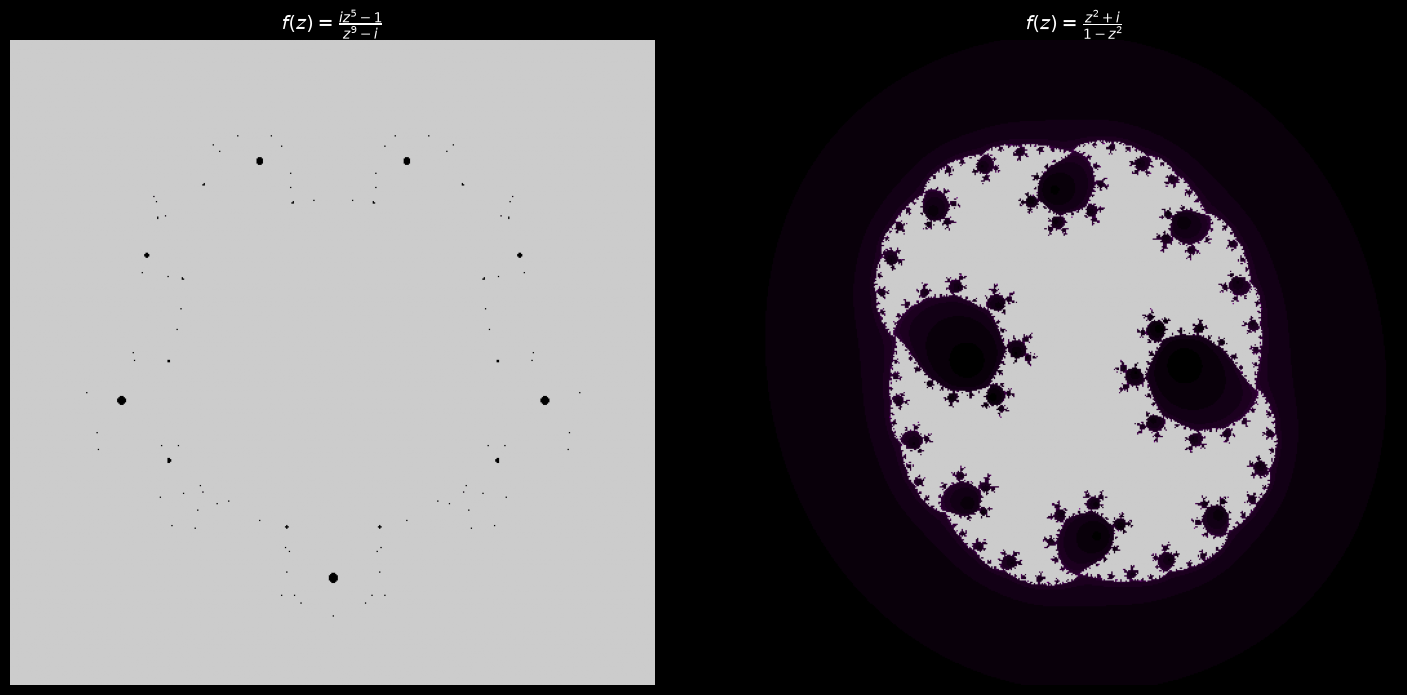

In [4]:
import numpy as np
from cmath import *
import matplotlib.pyplot as plt

def julia_set_func(f, im_width=500, im_height=500,
                   xmin=-2.1, xmax=2.1, ymin=-2.1, ymax=2.1,
                   zabs_max=10, nit_max=1000):
    xwidth = xmax - xmin
    yheight = ymax - ymin
    julia = np.zeros((im_width, im_height))

    for ix in range(im_width):
        for iy in range(im_height):
            nit = 0
            z = complex(ix / im_width * xwidth + xmin,
                        iy / im_height * yheight + ymin)
            try:
                while abs(z) <= zabs_max and nit < nit_max:
                    z = f(z)
                    nit += 1
            except (ZeroDivisionError, OverflowError):
                pass
            ratio = nit / nit_max
            julia[ix, iy] = ratio
    return julia

# f(z) = (i*z^5 - 1) / (z^9 - i)
def f1(z):
    return (1j * z**5 - 1) / (z**9 - 1j)

# f(z) = (z^2 + i) / (1 - z^2)
def f2(z):
    return (z**2 + 1j) / (1 - z**2)

julia_f1 = julia_set_func(f1, xmin=-1.5, xmax=1.5, ymin=-1.5, ymax=1.5)
julia_f2 = julia_set_func(f2, xmin=-3.0, xmax=3.0, ymin=-3.0, ymax=3.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(julia_f1.T, cmap='nipy_spectral',
               extent=[-1.5, 1.5, -1.5, 1.5])
axes[0].set_title(r'$f(z) = \frac{iz^5 - 1}{z^9 - i}$', fontsize=14)
axes[0].axis('off')

axes[1].imshow(julia_f2.T, cmap='nipy_spectral',
               extent=[-3, 3, -3, 3])
axes[1].set_title(r'$f(z) = \frac{z^2 + i}{1 - z^2}$', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.savefig("Sol_2_9d.pdf", bbox_inches='tight')
plt.show()